In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
df = pd.read_csv("C:\\Users\\ab\\OneDrive\\Desktop\\CUSTOM\\Telco_Customer_Churn_Dataset  (1).csv")
import pandas as pd
from sklearn.model_selection import train_test_split


Libraries imported successfully!


In [2]:


file_path = r"C:\Users\ab\OneDrive\Desktop\CUSTOM\Telco_Customer_Churn_Dataset  (1).csv"

df = pd.read_csv(file_path)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load the dataset
file_path = r"C:\Users\ab\OneDrive\Desktop\CUSTOM\Telco_Customer_Churn_Dataset  (1).csv"

df = pd.read_csv(file_path)

# 2. Clean column names
df.columns = df.columns.str.strip()

# 3. Replace blank spaces with missing values
df = df.replace(r"^\s*$", pd.NA, regex=True)

# 4. Convert TotalCharges to numeric
# Blank values become NaN and will be imputed later
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# 5. Remove unnecessary identifier column
columns_to_drop = ["customerID"]

df = df.drop(
    columns=[column for column in columns_to_drop if column in df.columns]
)

# 6. Separate features and target
target_column = "Churn"

if target_column not in df.columns:
    raise ValueError("The 'Churn' column was not found.")

X = df.drop(columns=[target_column])
y = df[target_column]

# 7. Split data before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# 9. Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 10. Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# 11. Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

# 12. Transform the training and testing data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Data preparation completed successfully.")
print(f"Original dataset shape: {df.shape}")
print(f"Training data shape: {X_train_processed.shape}")
print(f"Testing data shape: {X_test_processed.shape}")
print(f"Missing values in training data: {X_train.isna().sum().sum()}")
print(f"Missing values in testing data: {X_test.isna().sum().sum()}")

Data preparation completed successfully.
Original dataset shape: (7043, 20)
Training data shape: (5634, 45)
Testing data shape: (1409, 45)
Missing values in training data: 8
Missing values in testing data: 3


In [5]:
from sklearn.model_selection import train_test_split

# Reproducible split
RANDOM_STATE = 42

# X contains features and y contains the Churn target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    train_size=0.80,
    random_state=RANDOM_STATE,
    stratify=y
)

# Verify the split sizes
print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print("Training target:  ", y_train.shape)
print("Testing target:   ", y_test.shape)

# Verify representative Churn proportions
print("\nOriginal Churn distribution:")
print(y.value_counts(normalize=True).round(3))

print("\nTraining Churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features:  (1409, 19)
Training target:   (5634,)
Testing target:    (1409,)

Original Churn distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

Training Churn distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

Testing Churn distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data: ", X_test.shape)

Training data: (5634, 19)
Testing data:  (1409, 19)


In [7]:


from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Candidate models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Stratified cross-validation preserves the Churn proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_results = {}
model_pipelines = {}

for model_name, model in models.items():

    # The preprocessor should be the one created in Task 1
    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    model_results[model_name] = scores.mean()
    model_pipelines[model_name] = model_pipeline

# Compare model performance
results_df = (
    pd.DataFrame(
        list(model_results.items()),
        columns=["Model", "Mean ROC-AUC"]
    )
    .sort_values("Mean ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

print(results_df)

# Select the best model
best_model_name = results_df.loc[0, "Model"]
final_model = model_pipelines[best_model_name]

print(f"\nSelected model: {best_model_name}")
print(f"Mean cross-validation ROC-AUC: {results_df.loc[0, 'Mean ROC-AUC']:.4f}")

                 Model  Mean ROC-AUC
0    Gradient Boosting      0.849282
1  Logistic Regression      0.845950
2        Random Forest      0.822575
3        Decision Tree      0.818372

Selected model: Gradient Boosting
Mean cross-validation ROC-AUC: 0.8493


In [8]:
# Train the selected model
final_model.fit(X_train, y_train)

print("Model training completed successfully.")
print(f"Selected model: {best_model_name}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Training features: {X_train.shape[1]}")

Model training completed successfully.
Selected model: Gradient Boosting
Training samples: 5634
Training features: 19


In [9]:
# Generate predictions for the training data
y_train_pred = final_model.predict(X_train)

print("Training predictions generated successfully.")
print(f"Number of predictions: {len(y_train_pred)}")
print(f"Number of actual labels: {len(y_train)}")

Training predictions generated successfully.
Number of predictions: 5634
Number of actual labels: 5634


MODEL EVALUATION RESULTS
Positive class: Yes
Model: Gradient Boosting

Accuracy: 0.8055
Precision: 0.6761
Recall: 0.5134
F1-score: 0.5836
ROC-AUC: 0.8455

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.68      0.51      0.58       374

    accuracy                           0.81      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.80      0.81      0.80      1409

CONFUSION MATRIX
[[943  92]
 [182 192]]


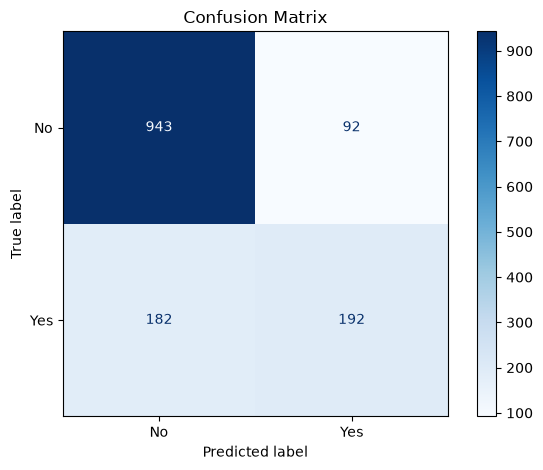

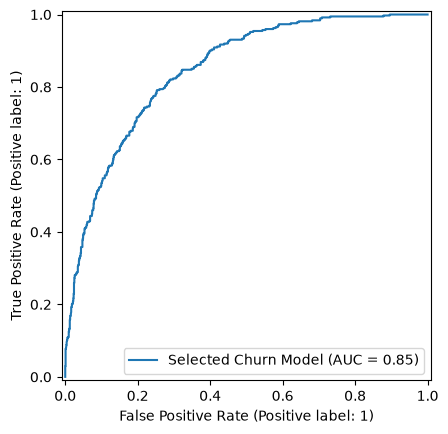

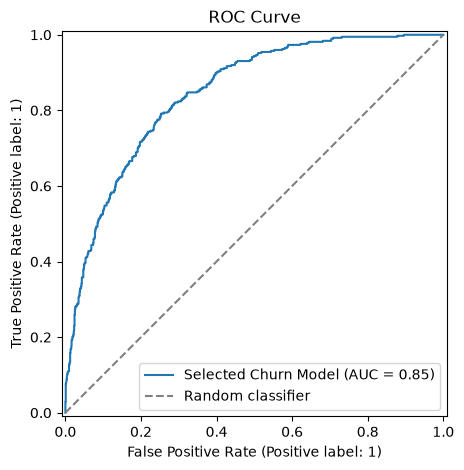

In [12]:
# TASK 6: MODEL EVALUATION

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Generate predictions on the testing dataset
y_test_pred = final_model.predict(X_test)

# 2. Generate probabilities for the positive class
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# 3. Get the model's class labels
model_classes = final_model.named_steps["model"].classes_
positive_label = model_classes[1]

# 4. Convert target labels to binary values for ROC-AUC
y_test_binary = (y_test == positive_label).astype(int)

# 5. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(
    y_test,
    y_test_pred,
    pos_label=positive_label,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    pos_label=positive_label,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    pos_label=positive_label,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test_binary,
    y_test_proba
)

# 6. Store and display the results
evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print("MODEL EVALUATION RESULTS")
print("=" * 35)
print(f"Positive class: {positive_label}")
print(f"Model: {best_model_name}\n")

for _, row in evaluation_results.iterrows():
    print(f"{row['Metric']}: {row['Score']:.4f}")

# 7. Display the classification report
print("\nCLASSIFICATION REPORT")
print("=" * 35)

print(classification_report(
    y_test,
    y_test_pred,
    labels=model_classes,
    target_names=[str(label) for label in model_classes],
    zero_division=0
))

# 8. Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=model_classes
)

print("CONFUSION MATRIX")
print("=" * 35)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model_classes
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()
best_model_name = "Selected Churn Model"

RocCurveDisplay.from_predictions(
    y_test_binary,
    y_test_proba,
    name=best_model_name
)
# 9. Plot the ROC curve
RocCurveDisplay.from_predictions(
    y_test_binary,
    y_test_proba,
    name=best_model_name
)

plt.title("ROC Curve")
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.legend()
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path
import joblib
import pandas as pd
import subprocess
import sys

# Folder for all saved project files
save_folder = Path("customer_churn_final_project")
save_folder.mkdir(exist_ok=True)

# Save trained model
joblib.dump(
    final_model,
    save_folder / "trained_model.pkl"
)

# Save predictions and probabilities
pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred,
    "Probability": y_test_proba
}).to_csv(
    save_folder / "predictions.csv",
    index=False
)

# Save evaluation metrics
pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
}).to_csv(
    save_folder / "metrics.csv",
    index=False
)

# Save cleaned dataset
df.to_csv(
    save_folder / "cleaned_dataset.csv",
    index=False
)

# Save installed packages
with open(save_folder / "requirements.txt", "w") as file:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=file,
        check=True
    )

print("Everything was saved in:")
print(save_folder.resolve())

Everything was saved in:
C:\Users\ab\OneDrive\Desktop\CUSTOM\customer_churn_final_project
